In [1]:
import numpy as np

# Create sparse design matrix X with most entries zero
np.random.seed(42)
N, P = 100, 20  # 100 samples, 20 features

# Sparse matrix: 90% zeros
X_sparse = np.random.binomial(1, 0.1, size=(N, P)) * np.random.randn(N, P)

# True sparse coefficients
true_beta = np.zeros(P)
true_beta[[0, 4, 9]] = [2.0, -1.0, 1.5]

# Generate response with noise
y_sparse = X_sparse @ true_beta + np.random.randn(N) * 0.3

import pandas as pd
import matplotlib.pyplot as plt


X_sparse.shape, y_sparse.shape

((100, 20), (100,))

In [2]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.linear_model import LassoCV

lasso_cv_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('lasso', LassoCV(cv=5))
])
lasso_cv_pipe.fit(X_sparse, y_sparse)
y_pred_lasso = lasso_cv_pipe.predict(X_sparse)
mse_lasso = mean_squared_error(y_sparse, y_pred_lasso)
r2_lasso = r2_score(y_sparse, y_pred_lasso)


coef_lasso = lasso_cv_pipe.named_steps['lasso'].coef_
zero_lasso = np.sum(np.abs(coef_lasso) < 1e-8)

# Adative Lasso regression pipeline
from jax_model_lib.jax_sklearn_adapter import JaxSparseRegressor

pipe = Pipeline([
    ('scale', StandardScaler()),
    ('jax_model', JaxSparseRegressor(
    lam_prior='group',
    lik='normal'))
])
pipe.fit(X_sparse, y_sparse)
y_pred_jax = pipe.predict(X_sparse)
mse_jax = mean_squared_error(y_sparse, y_pred_jax)
r2_jax = r2_score(y_sparse, y_pred_jax)

coef_jax = pipe.named_steps['jax_model'].get_coefficients()
zero_jax = np.sum(np.abs(coef_jax) < 1e-8)


In [3]:
print(f"Lasso Regression     MSE: {mse_lasso:.4f}, R²: {r2_lasso:.4f}")
print(f"JAX Sparse Regressor MSE: {mse_jax:.4f}, R²: {r2_jax:.4f}")

print(f"Lasso shrank to 0:      {zero_lasso} / {len(coef_lasso)}")
print(f"JAX sparse shrank to 0: {zero_jax} / {len(coef_jax)}")

Lasso Regression     MSE: 0.0813, R²: 0.8316
JAX Sparse Regressor MSE: 0.0740, R²: 0.8467
Lasso shrank to 0:      13 / 20
JAX sparse shrank to 0: 2 / 20


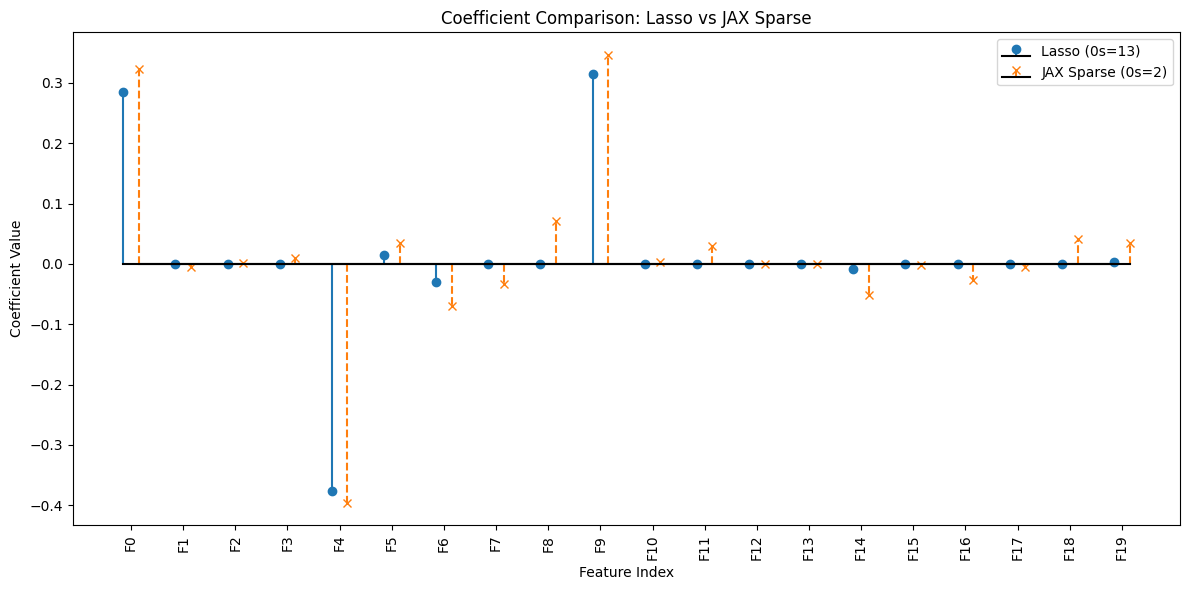

In [4]:
# Plot
x = np.arange(len(coef_lasso))
plt.figure(figsize=(12, 6))
plt.stem(x - 0.15, coef_lasso, linefmt='C0-', markerfmt='C0o', basefmt='k-', label=f'Lasso (0s={zero_lasso})')
plt.stem(x + 0.15, coef_jax, linefmt='C1--', markerfmt='C1x', basefmt='k-', label=f'JAX Sparse (0s={zero_jax})')
plt.xticks(x, [f"F{i}" for i in x], rotation=90)
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.title("Coefficient Comparison: Lasso vs JAX Sparse")
plt.legend()
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from jax_model_lib.jax_sklearn_adapter import JaxSparseRegressor

# Prepare synthetic data
N, P = 80, 20
X = np.random.randn(N, P)
true_beta = np.zeros(P)
true_beta[:4] = [2.0, -1.0, 1.5, -1.2]
y = X @ true_beta + np.random.randn(N) * 0.5
y_binary = (y > np.median(y)).astype(float)
y_count = np.random.poisson(lam=np.exp(np.clip(X[:, 0], 0, 4))).astype(float)

# Helper
def get_group_vars(P):
    G = int(np.ceil(np.sqrt(P)))
    return {
        'log_gamma': np.zeros(G, dtype=float),
        'groups': np.repeat(np.arange(G), P // G + 1)[:P].astype(float)
    }

# Dummy custom functions
def custom_mse(vv, Xb, yb):
    import jax.numpy as jnp
    r = Xb @ vv['beta'] - yb
    loss = jnp.sum(r**2)
    grad = {'beta': 2 * Xb.T @ r}
    return loss, grad

def dummy_prior(x, pv, mod):
    import jax.numpy as jnp
    loss = jnp.sum(x**2)
    grad = {'lam': 2 * x}
    return loss, grad

def dummy_prox(vv, tau, lam, lr): return vv  # No-op prox

# Parameter grid (selectively representative, not exhaustive)
cases = [
    {'lam_prior': 'adaptive', 'lik': 'normal'},
    {'lam_prior': 'group', 'lik': 'bernoulli', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'group', 'lik': 'poisson', 'lam_prior_vars': get_group_vars(P)},
    {'lam_prior': 'adaptive', 'lik': 'none', 'custom_nll_grad': custom_mse},
    {'lam_prior': 'adaptive', 'lik': 'normal', 'custom_prior': dummy_prior},
    {'lam_prior': 'group', 'lik': 'normal', 'custom_prox': dummy_prox, 'lam_prior_vars': get_group_vars(P)}
]

print("Testing parameter combinations:")
for i, case in enumerate(cases):
    try:
        y_target = {
            'normal': y,
            'none': y,
            'bernoulli': y_binary,
            'poisson': y_count
        }[case['lik']]

        model = JaxSparseRegressor(
            tau0=0.8,
            max_iters=10,
            lr_pre=0.01,
            mb_size=20,
            invlam=False,
            logprox=False,
            track=True,
            **case
        )

        pipe = Pipeline([
            ('scale', StandardScaler()),
            ('jax_model', model)
        ])

        pipe.fit(X, y_target)
        y_pred = pipe.predict(X)
        r2 = r2_score(y_target, y_pred)
        nonzero = np.sum(np.abs(pipe.named_steps['jax_model'].get_coefficients()) > 1e-8)
        print(f"Case {i+1}: lam_prior={case['lam_prior']}, lik={case['lik']}, R²={r2:.3f}, nonzero={nonzero}")
    except Exception as e:
        print(f"Case {i+1} failed: {str(e)}")

Testing parameter combinations:
Case 1 failed: 'NoneType' object is not iterable
Case 2 failed: grad requires real- or complex-valued inputs (input dtype that is a sub-dtype of np.inexact), but got int64. If you want to use Boolean- or integer-valued inputs, use vjp or set allow_int to True.
Case 3 failed: grad requires real- or complex-valued inputs (input dtype that is a sub-dtype of np.inexact), but got int64. If you want to use Boolean- or integer-valued inputs, use vjp or set allow_int to True.
Case 4 failed: 'NoneType' object is not iterable
Case 5 failed: 'NoneType' object is not iterable
Case 6 failed: grad requires real- or complex-valued inputs (input dtype that is a sub-dtype of np.inexact), but got int64. If you want to use Boolean- or integer-valued inputs, use vjp or set allow_int to True.
